# Generative Adversarial Networks (GAN)

**Paper:** Goodfellow et al. (2014), *Generative Adversarial Nets*, arXiv:1406.2661

This notebook implements a from-scratch GAN with a generator/discriminator MLP pair, the minimax training loop, training on MNIST, and an animation of the generated digits over training.

## Key Idea

Two networks compete in a game:
- **Generator G**: maps random noise z → fake image, tries to fool D
- **Discriminator D**: classifies image as real or fake, tries to not be fooled

Through this adversarial process, G learns to produce samples matching the true data distribution — all via backpropagation, no MCMC or approximate inference needed.

## 1. Setup & Imports

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.animation as animation
from IPython.display import Image

# Set random seed for reproducibility
torch.manual_seed(42)
np.random.seed(42)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {device}')

Device: cpu


## 2. Hyperparameters

Following the original paper's framework with modern best practices for stable GAN training.

In [2]:
latent_dim = 100       # Dimension of noise vector z
img_dim = 784           # Flattened MNIST image (28x28)
hidden_dim = 256        # Hidden layer size for both G and D
lr = 0.0002             # Learning rate
batch_size = 64         # Minibatch size
num_epochs = 100        # Training epochs
k_steps = 1             # Discriminator steps per generator step (as in paper)
beta1 = 0.5             # Adam beta1 (reduced momentum for GAN stability)
sample_every = 5        # Save fixed-noise samples every 5 epochs (plus epoch 1)

## 3. Data Loading (MNIST)

Load MNIST via torchvision, flatten images to 784-dim vectors, and scale pixels to **[-1, 1]** (`Normalize((0.5,), (0.5,))` maps 0 → -1 and 1 → +1).

Why [-1, 1] and not [0, 1]? The generator's last layer must produce the same range as the data. [-1, 1] pairs with a Tanh output, which is the standard choice for GANs. An earlier version of this notebook used [0, 1] with a Sigmoid output, and the generator collapsed in the first epoch: it drew the same white-on-black blob for every noise vector and never recovered. See section 4.

For plotting we convert back with `to_img(x) = (x + 1) / 2`.

MNIST samples: 60000
Batches per epoch: 937
Pixel range: [-1.0, 1.0]


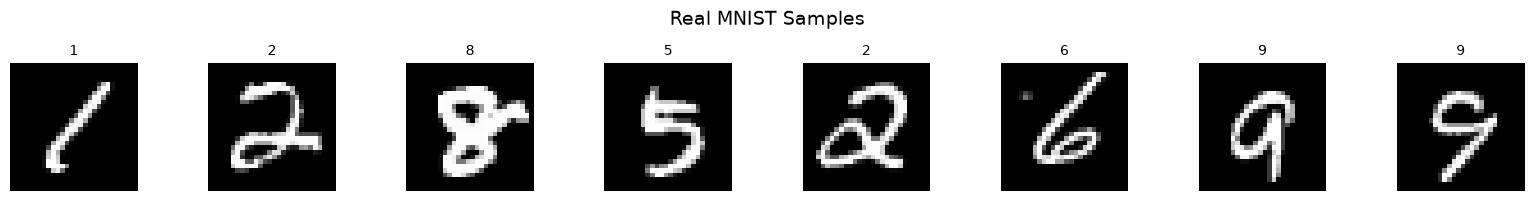

In [3]:
transform = transforms.Compose([
    transforms.ToTensor(),                  # Scales to [0, 1]
    transforms.Normalize((0.5,), (0.5,)),   # Shifts to [-1, 1] to match the generator's Tanh output
    transforms.Lambda(lambda x: x.view(-1))  # Flatten to 784
])

dataset = torchvision.datasets.MNIST(
    root='./data', train=True, download=True, transform=transform
)
dataloader = DataLoader(dataset, batch_size=batch_size, shuffle=True, drop_last=True)

def to_img(x):
    """Map [-1, 1] back to [0, 1] for plotting."""
    return (x + 1) / 2

print(f'MNIST samples: {len(dataset)}')
print(f'Batches per epoch: {len(dataloader)}')
print(f'Pixel range: [{dataset[0][0].min():.1f}, {dataset[0][0].max():.1f}]')

# Visualize a few real samples
real_batch = next(iter(dataloader))
fig, axes = plt.subplots(1, 8, figsize=(16, 2))
for i in range(8):
    axes[i].imshow(to_img(real_batch[0][i]).view(28, 28).numpy(), cmap='gray', vmin=0, vmax=1)
    axes[i].axis('off')
    axes[i].set_title(str(real_batch[1][i].item()), fontsize=10)
plt.suptitle('Real MNIST Samples', fontsize=14)
plt.tight_layout()
plt.show()

## 4. Generator Network (G)

Maps noise vector z (100-dim, drawn from a standard Gaussian) to a 784-dim image vector.
- 3-layer MLP with LeakyReLU activations
- **Tanh** output to produce values in [-1, 1], the same range as the normalized data

The paper's generator used a mix of ReLU and sigmoid activations; we use LeakyReLU in the hidden layers, which is a common modern choice.

**Why Tanh instead of Sigmoid?** We tested both on this exact setup. With [0, 1] data and a Sigmoid output, the generator collapsed within the first epoch on every seed we tried: almost every pixel was pushed to pure black or pure white, every noise vector gave the same image, and the discriminator won outright. With [-1, 1] data and Tanh, the same networks and optimizer learn varied digits. A likely reason: Tanh is centred on zero and its slope is up to 4× steeper than Sigmoid's, so the generator gets a stronger, better-balanced learning signal.

In [4]:
class Generator(nn.Module):
    def __init__(self, latent_dim, hidden_dim, img_dim):
        super(Generator, self).__init__()
        self.net = nn.Sequential(
            nn.Linear(latent_dim, hidden_dim),
            nn.LeakyReLU(0.2),
            nn.Linear(hidden_dim, hidden_dim),
            nn.LeakyReLU(0.2),
            nn.Linear(hidden_dim, img_dim),
            nn.Tanh()  # Output in [-1, 1] to match normalized MNIST
        )

    def forward(self, z):
        return self.net(z)

G = Generator(latent_dim, hidden_dim, img_dim).to(device)
print(G)
print(f'Generator parameters: {sum(p.numel() for p in G.parameters()):,}')

Generator(
  (net): Sequential(
    (0): Linear(in_features=100, out_features=256, bias=True)
    (1): LeakyReLU(negative_slope=0.2)
    (2): Linear(in_features=256, out_features=256, bias=True)
    (3): LeakyReLU(negative_slope=0.2)
    (4): Linear(in_features=256, out_features=784, bias=True)
    (5): Tanh()
  )
)
Generator parameters: 293,136


## 5. Discriminator Network (D)

Classifies input image as real or fake.
- 3-layer MLP with LeakyReLU and Dropout
- Outputs a single raw score (a *logit*). `sigmoid(logit)` is the probability that the input is real. We leave the sigmoid out of the network and let the loss apply it (section 6), which is numerically safer.

The paper's discriminator used maxout activations with dropout; we use LeakyReLU + Dropout, a common modern substitute.

In [5]:
class Discriminator(nn.Module):
    def __init__(self, img_dim, hidden_dim):
        super(Discriminator, self).__init__()
        self.net = nn.Sequential(
            nn.Linear(img_dim, hidden_dim),
            nn.LeakyReLU(0.2),
            nn.Dropout(0.3),
            nn.Linear(hidden_dim, hidden_dim),
            nn.LeakyReLU(0.2),
            nn.Dropout(0.3),
            nn.Linear(hidden_dim, 1)  # Raw logit; sigmoid(logit) = P(real)
        )

    def forward(self, x):
        return self.net(x)

D = Discriminator(img_dim, hidden_dim).to(device)
print(D)
print(f'Discriminator parameters: {sum(p.numel() for p in D.parameters()):,}')

Discriminator(
  (net): Sequential(
    (0): Linear(in_features=784, out_features=256, bias=True)
    (1): LeakyReLU(negative_slope=0.2)
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=256, out_features=256, bias=True)
    (4): LeakyReLU(negative_slope=0.2)
    (5): Dropout(p=0.3, inplace=False)
    (6): Linear(in_features=256, out_features=1, bias=True)
  )
)
Discriminator parameters: 267,009


## 6. Loss Function & Optimizers

### Adversarial Loss (BCE)

The GAN objective is:
```
min_G max_D V(D,G) = E[log D(x)] + E[log(1 - D(G(z)))]
```

We implement this using Binary Cross Entropy (BCE):
- **D loss**: BCE(D(real), 1) + BCE(D(fake), 0). D wants to classify real as 1 and fake as 0.
- **G loss (non-saturating)**: BCE(D(fake), 1). G wants D to classify fake as 1 (fool D).

The non-saturating generator loss (maximizing log D(G(z)) instead of minimizing log(1 - D(G(z)))) is the practical trick from the paper that provides stronger gradients early in training.

### Why `BCEWithLogitsLoss`

`BCEWithLogitsLoss` combines the sigmoid and the BCE in one numerically stable step. A separate `Sigmoid` + `BCELoss` has a hidden trap: once D becomes very sure a fake is fake (probability below about 1e-12), PyTorch's `BCELoss` clamps its gradient. The learning signal reaching G then drops to almost exactly zero (about 1e-23 when G_loss ≈ 79), so G stops learning for good. With logits, the gradient on that score stays at about -1 no matter how confident D is.

On its own this change did **not** stop the collapse in our tests; the Tanh output in section 4 is what fixed it. `BCEWithLogitsLoss` is the safety net that keeps G able to recover if D ever gets far ahead.

In [6]:
criterion = nn.BCEWithLogitsLoss()  # sigmoid + BCE in one numerically stable op

optimizer_G = optim.Adam(G.parameters(), lr=lr, betas=(beta1, 0.999))
optimizer_D = optim.Adam(D.parameters(), lr=lr, betas=(beta1, 0.999))

# Real and fake labels
real_label = 1.0
fake_label = 0.0

print('Loss: BCEWithLogitsLoss')
print(f'Optimizer: Adam (lr={lr}, beta1={beta1})')
print(f'G loss: non-saturating (maximize log D(G(z)))')
print(f'D loss: maximize log D(x) + log(1 - D(G(z)))')

Loss: BCEWithLogitsLoss
Optimizer: Adam (lr=0.0002, beta1=0.5)
G loss: non-saturating (maximize log D(G(z)))
D loss: maximize log D(x) + log(1 - D(G(z)))


## 7. Training Loop

Following Algorithm 1 from the paper:
1. Sample minibatch of noise z and real examples x
2. Update D (k=1 steps): maximize log D(x) + log(1 - D(G(z)))
3. Update G (1 step): maximize log D(G(z)) [non-saturating]

We save generated samples from a fixed noise vector after epoch 1 and every 5 epochs, to show the progression.

**How to read the log.** D(x) and D(G(z)) are D's average "probability real" over the whole epoch, for real images and for fakes. In a healthy run D(G(z)) does not fall to 0: D keeps some doubt about the fakes, and both losses stay in a small, similar range. If D(G(z)) drops to 0.000 and G_loss explodes, D has won and G is no longer learning.

In [7]:
# Fixed noise for consistent visualization across epochs
fixed_noise = torch.randn(64, latent_dim, device=device)

# Storage for animation
img_list = []       # generated samples from fixed_noise
sample_epochs = []  # epoch number (1-based) for each entry in img_list
G_losses = []
D_losses = []

print('Starting training...')
print(f'Epochs: {num_epochs}, Batch size: {batch_size}, k_steps: {k_steps}')
print('-' * 80)

for epoch in range(1, num_epochs + 1):
    epoch_D_loss = 0.0
    epoch_G_loss = 0.0
    epoch_D_x = 0.0
    epoch_D_G_z = 0.0
    num_batches = 0

    for i, (real_images, _) in enumerate(dataloader):
        batch_size_curr = real_images.size(0)
        real_images = real_images.to(device)

        # Labels
        real_labels = torch.full((batch_size_curr, 1), real_label, device=device)
        fake_labels = torch.full((batch_size_curr, 1), fake_label, device=device)

        # ---- Discriminator Update (k=1 step) ----
        optimizer_D.zero_grad()

        # D loss on real
        output_real = D(real_images)
        loss_D_real = criterion(output_real, real_labels)

        # D loss on fake
        noise = torch.randn(batch_size_curr, latent_dim, device=device)
        fake_images = G(noise)
        output_fake = D(fake_images.detach())  # detach so G doesn't get gradients
        loss_D_fake = criterion(output_fake, fake_labels)

        loss_D = loss_D_real + loss_D_fake
        loss_D.backward()
        optimizer_D.step()

        # ---- Generator Update (1 step, non-saturating) ----
        optimizer_G.zero_grad()

        noise = torch.randn(batch_size_curr, latent_dim, device=device)
        fake_images = G(noise)
        output = D(fake_images)
        # Non-saturating: G wants D to output 1 (real) for fake images
        loss_G = criterion(output, real_labels)
        loss_G.backward()
        optimizer_G.step()

        epoch_D_loss += loss_D.item()
        epoch_G_loss += loss_G.item()
        epoch_D_x += torch.sigmoid(output_real).mean().item()  # logits -> probabilities
        epoch_D_G_z += torch.sigmoid(output).mean().item()
        num_batches += 1

    avg_D_loss = epoch_D_loss / num_batches
    avg_G_loss = epoch_G_loss / num_batches
    G_losses.append(avg_G_loss)
    D_losses.append(avg_D_loss)

    # Save generated samples at regular intervals
    if epoch == 1 or epoch % sample_every == 0:
        with torch.no_grad():
            fake = G(fixed_noise).cpu().view(-1, 1, 28, 28)
        img_list.append(to_img(fake))
        sample_epochs.append(epoch)
        print(f'Epoch [{epoch:3d}/{num_epochs}] | D_loss: {avg_D_loss:.4f} | G_loss: {avg_G_loss:.4f} | '
              f'D(x): {epoch_D_x / num_batches:.3f} | D(G(z)): {epoch_D_G_z / num_batches:.3f}')

print('-' * 80)
print('Training complete!')

Starting training...
Epochs: 100, Batch size: 64, k_steps: 1
--------------------------------------------------------------------------------


Epoch [  1/100] | D_loss: 0.7293 | G_loss: 1.8502 | D(x): 0.797 | D(G(z)): 0.232


Epoch [  5/100] | D_loss: 0.5185 | G_loss: 2.6238 | D(x): 0.838 | D(G(z)): 0.141


Epoch [ 10/100] | D_loss: 0.6811 | G_loss: 2.0098 | D(x): 0.780 | D(G(z)): 0.206


Epoch [ 15/100] | D_loss: 0.9075 | G_loss: 1.4872 | D(x): 0.700 | D(G(z)): 0.289


...

Epoch [ 80/100] | D_loss: 1.1873 | G_loss: 1.0161 | D(x): 0.592 | D(G(z)): 0.403


Epoch [ 85/100] | D_loss: 1.1852 | G_loss: 1.0224 | D(x): 0.593 | D(G(z)): 0.401


Epoch [ 90/100] | D_loss: 1.1926 | G_loss: 1.0132 | D(x): 0.590 | D(G(z)): 0.403


Epoch [ 95/100] | D_loss: 1.1965 | G_loss: 1.0071 | D(x): 0.588 | D(G(z)): 0.405


Epoch [100/100] | D_loss: 1.1981 | G_loss: 0.9960 | D(x): 0.588 | D(G(z)): 0.408
--------------------------------------------------------------------------------
Training complete!


## 8. Loss Curves

Visualize the adversarial loss dynamics over training. At the paper's theoretical equilibrium, D outputs 1/2 for everything. Our D loss is the sum of two BCE terms, so it would sit at 2·log 2 ≈ 1.39, and the G loss at log 2 ≈ 0.69. Real training with small networks does not reach this point exactly. What matters is that neither loss runs away: D's loss should not fall to 0, and G's loss should not keep climbing.

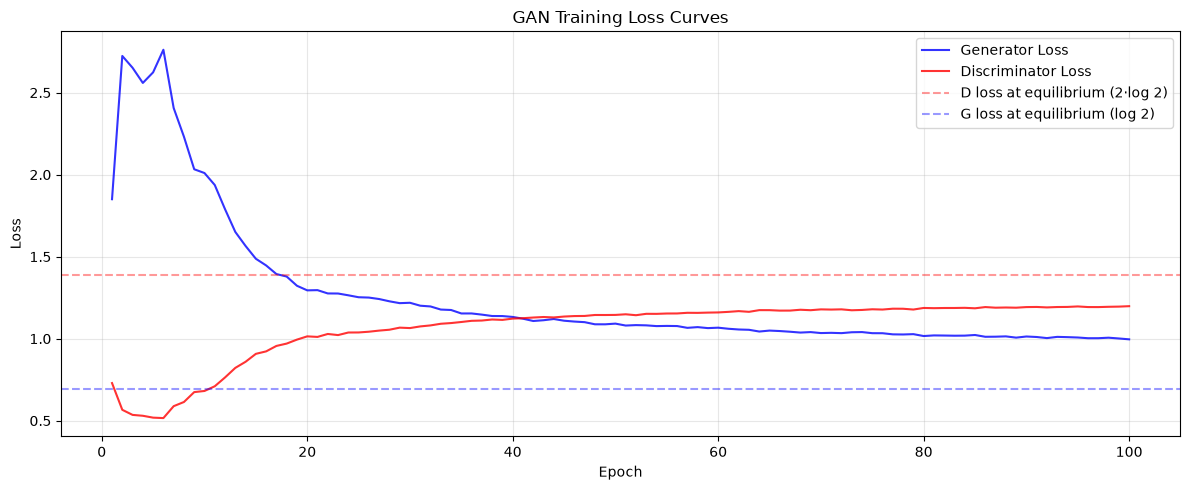

In [8]:
plt.figure(figsize=(12, 5))
epochs_axis = range(1, len(G_losses) + 1)
plt.plot(epochs_axis, G_losses, label='Generator Loss', alpha=0.8, color='blue')
plt.plot(epochs_axis, D_losses, label='Discriminator Loss', alpha=0.8, color='red')
plt.axhline(y=2 * np.log(2), color='red', linestyle='--', alpha=0.4, label='D loss at equilibrium (2·log 2)')
plt.axhline(y=np.log(2), color='blue', linestyle='--', alpha=0.4, label='G loss at equilibrium (log 2)')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('GAN Training Loss Curves')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 9. Generated Samples

The same 8 fixed noise vectors passed through the generator at different points in training. Each column is one noise vector, so you can watch a single sample change over time.

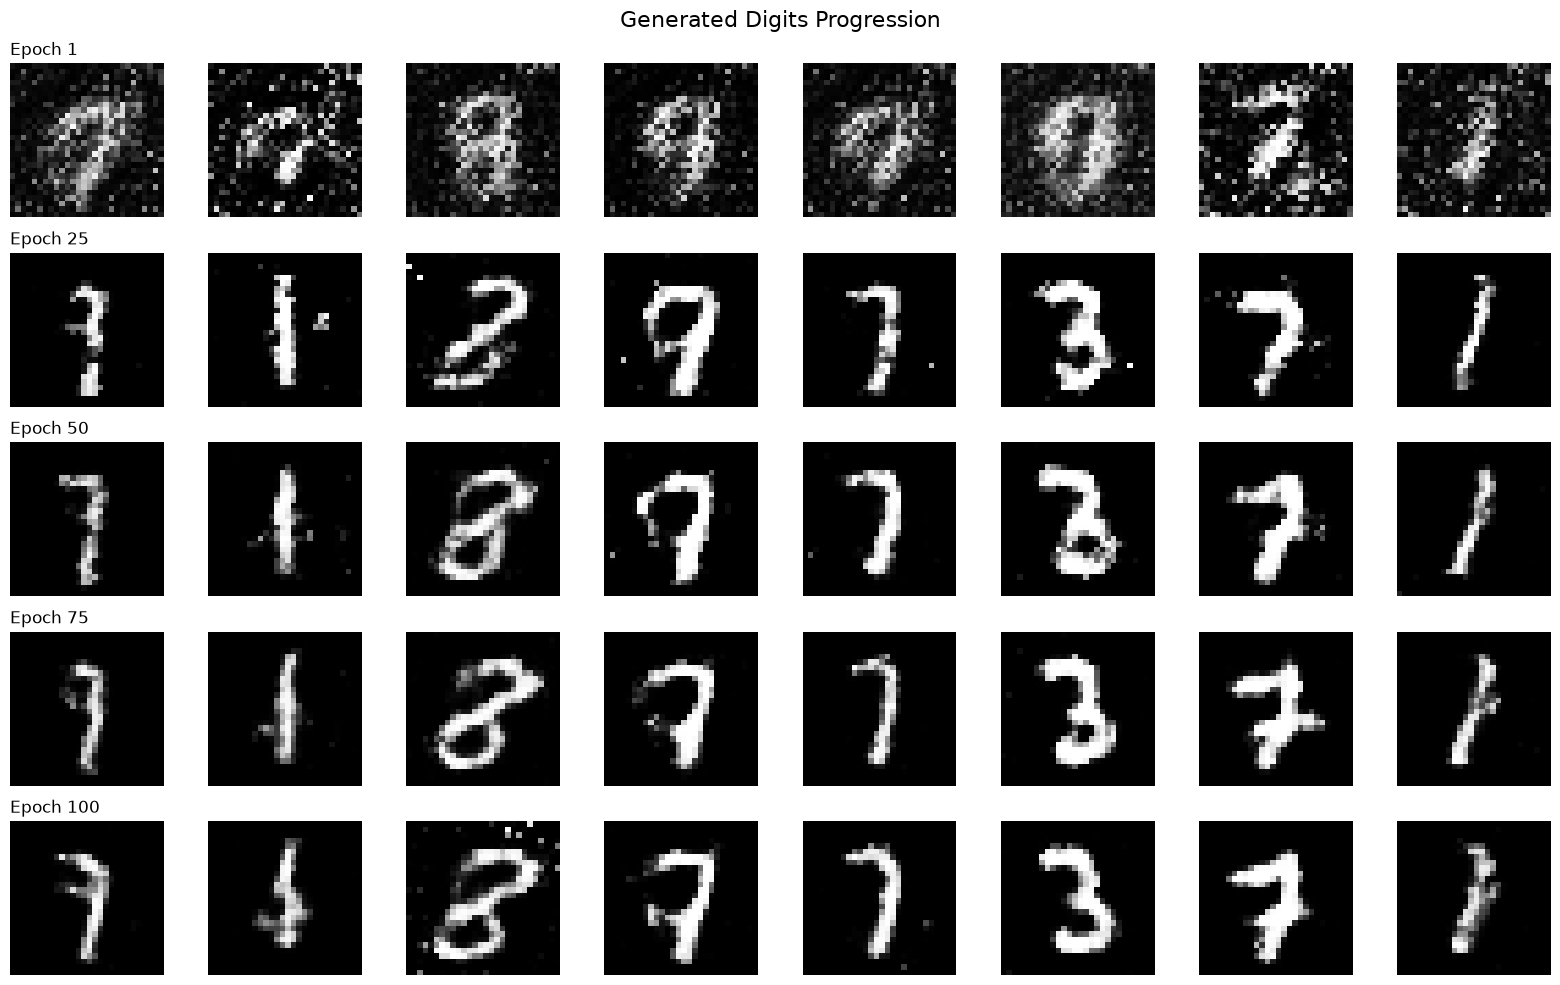

In [9]:
# Show generated digits at different stages
stages = [0, len(img_list)//4, len(img_list)//2, 3*len(img_list)//4, len(img_list)-1]

fig, axes = plt.subplots(len(stages), 8, figsize=(16, 2*len(stages)))
for row, stage in enumerate(stages):
    for col in range(8):
        axes[row, col].imshow(img_list[stage][col, 0].numpy(), cmap='gray', vmin=0, vmax=1)
        axes[row, col].axis('off')
        if col == 0:
            axes[row, col].set_title(f'Epoch {sample_epochs[stage]}', fontsize=12, loc='left')
plt.suptitle('Generated Digits Progression', fontsize=16)
plt.tight_layout()
plt.show()

## 10. Real vs Fake Comparison

Side-by-side comparison of real MNIST digits and generated digits after full training.

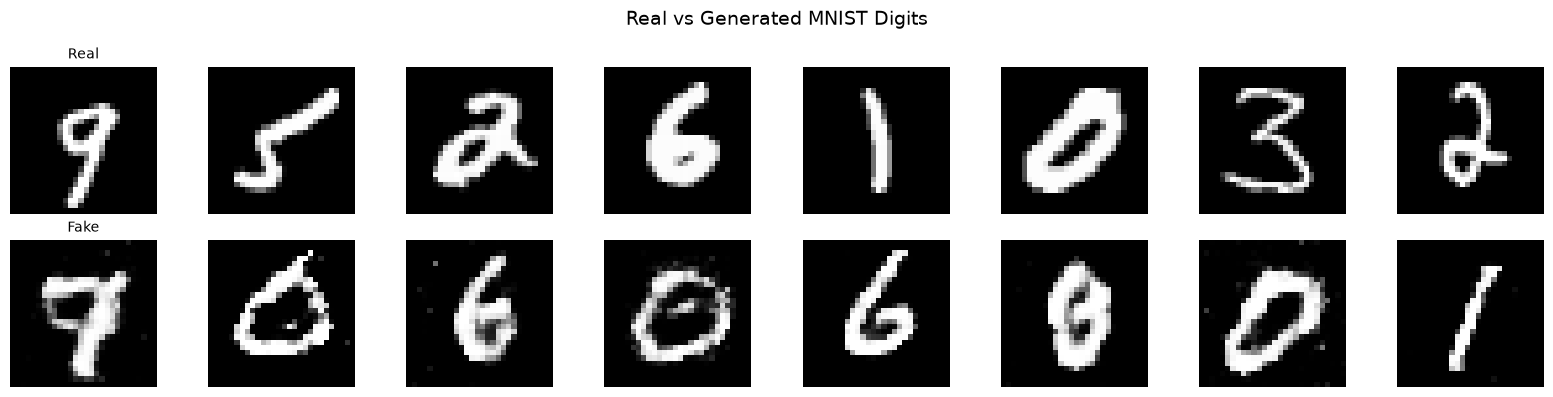

In [10]:
# Real vs Fake comparison
real_batch = next(iter(dataloader))
real_imgs = to_img(real_batch[0][:8]).view(-1, 28, 28).numpy()

with torch.no_grad():
    fake_imgs = to_img(G(torch.randn(8, latent_dim, device=device))).cpu().view(-1, 28, 28).numpy()

fig, axes = plt.subplots(2, 8, figsize=(16, 4))
for col in range(8):
    axes[0, col].imshow(real_imgs[col], cmap='gray', vmin=0, vmax=1)
    axes[0, col].axis('off')
    axes[0, col].set_title('Real', fontsize=10) if col == 0 else None
    axes[1, col].imshow(fake_imgs[col], cmap='gray', vmin=0, vmax=1)
    axes[1, col].axis('off')
    axes[1, col].set_title('Fake', fontsize=10) if col == 0 else None
plt.suptitle('Real vs Generated MNIST Digits', fontsize=14)
plt.tight_layout()
plt.show()

## 11. Animation: Generated Digits Over Training

This animation passes the same 64 fixed noise vectors through the generator at each saved epoch, so you can watch each sample change as G learns. It is saved as a small GIF (`gan_progress.gif`) and shown below.

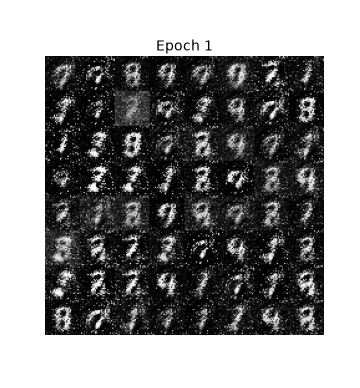

In [11]:
# Create animation of generated digits over training
fig, ax = plt.subplots(figsize=(5, 5.4))
ax.axis('off')

# Use 8x8 grid of the 64 fixed-noise samples
ims = []
for img_batch, epoch_num in zip(img_list, sample_epochs):
    grid = img_batch[:64, 0].numpy()  # (64, 28, 28)
    grid_img = grid.reshape(8, 8, 28, 28).transpose(0, 2, 1, 3).reshape(8 * 28, 8 * 28)
    im = ax.imshow(grid_img, cmap='gray', vmin=0, vmax=1, animated=True)
    title = ax.text(0.5, 1.02, f'Epoch {epoch_num}', transform=ax.transAxes,
                    ha='center', fontsize=14, animated=True)
    ims.append([im, title])

ani = animation.ArtistAnimation(fig, ims, interval=500, blit=True, repeat_delay=2000)
ani.save('gan_progress.gif', writer=animation.PillowWriter(fps=2), dpi=72)
plt.close(fig)

# Display animation
Image(filename='gan_progress.gif')

## 12. Summary

### What we built
- A **generator MLP** that maps 100-dim Gaussian noise → 784-dim MNIST-like images (Tanh output in [-1, 1])
- A **discriminator MLP** that scores images as real or fake (raw logit + `BCEWithLogitsLoss`)
- The **minimax adversarial training loop** (Algorithm 1 from the paper) with k=1, run for **100 epochs**
- **Non-saturating generator loss** for stronger early-training gradients
- **Visualization and a GIF animation** of the same 64 noise vectors over training

### What the run above shows
1. **Epoch 1:** grey, noisy blobs with a rough digit outline. D is clearly ahead (D(G(z)) ≈ 0.2).
2. **By about epoch 20–25:** clear digit shapes. Each fixed noise vector has turned into its own digit, so the samples differ from each other (no mode collapse).
3. **Epochs 25–100:** the same digits get cleaner strokes and less speckle. The changes are gradual; most of the learning happens in the first 25 epochs.
4. **Final quality:** most samples are recognizable handwritten digits, and the 64-sample grid covers many different digits. They are still clearly rougher than real MNIST: some strokes are blotchy or broken, a few samples are hard to read, and stray dots remain. That is typical for a small MLP GAN; convolutional GANs (DCGAN) do much better.
5. **Loss dynamics:** G's loss falls and D's loss rises during the first ~20 epochs, then both level off close together (about 1.0 for G and 1.2 for D). Neither runs away. D(G(z)) settles around 0.4 and D(x) around 0.6: D still does a bit better than chance, so the game has not reached the paper's ideal equilibrium (D = 0.5 everywhere), but G keeps getting a useful learning signal.

Exact numbers vary slightly between runs and hardware (CPU vs GPU), but in our tests on several random seeds the pattern was the same.

### What went wrong in the earlier version
An earlier version of this notebook used [0, 1] pixels with a Sigmoid generator output and a Sigmoid + `BCELoss` discriminator. It collapsed in the first epoch: every noise vector gave the same almost pure black-and-white blob, D(G(z)) fell to 0.000 and G_loss climbed to ~80. At that point the gradient reaching G was effectively zero, so it never recovered. Switching to [-1, 1] data with a Tanh output fixed the collapse; `BCEWithLogitsLoss` keeps the gradient alive if D ever gets far ahead again.

### Paper reference
Goodfellow, I., Pouget-Abadie, J., Mirza, M., Xu, B., Warde-Farley, D., Ozair, S., Courville, A., & Bengio, Y. (2014). *Generative Adversarial Nets.* arXiv:1406.2661.